In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GroupShuffleSplit
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GroupKFold

### How the data was joined

**Source tables**
- `price_history.parquet`: daily price snapshots, one row per **event per day** (1,616,449 rows, keyed by `eventId`). The target, `medianPrice`, comes from here.
- `joined_table.csv`: one row per **show** (29,613 rows), built in `07_joined_table.ipynb`. It joins `shows.csv` to `artists.csv` on `artist_key` and to `venues.csv` on `venue_key`, and keeps each show's `event_id`. So each row already has its artist's and venue's features.

**Why we don't join on artist**
Artist information is already attached to each show. Most artists play several shows, so joining the price history on artist name would be many-to-many. Each price snapshot would be copied onto every show by that artist.

**Final join**
We joined the price history to the show table on `eventId` = `event_id` (many-to-one: many daily snapshots per show). This is an inner join, keeping 1,275,865 snapshot rows (78.9%) covering all 29,613 shows. The remaining ~16.5k events in the price history aren't in the shows table and were dropped.

**Leakage control**
- We dropped the show table's `price_median` and `log_price_median`, because they summarize the target.
- We dropped its single-snapshot `listings`, `days_to_show` and `n_priced_days`, because the price history has daily versions of these.
- The train/test split is grouped by `eventId`, so snapshots of the same show never appear in both the training and test sets.


In [ ]:
prices = pd.read_parquet("../data/price_history.parquet")
shows = pd.read_csv("../data/joined_table.csv")

In [3]:
shows = shows.drop(columns=["price_median", "log_price_median",
                            "listings", "days_to_show", "n_priced_days"])

df = prices.merge(shows, left_on="eventId", right_on="event_id",
                  how="inner", validate="many_to_one")
print(f"price rows {len(prices):,} -> {len(df):,} after join "
      f"({df['eventId'].nunique():,} events)")

price rows 1,616,449 -> 1,275,865 after join (29,613 events)


In [4]:
y = df["medianPrice"]   # prices are very right-skewed

num_cols = ["daysToEvent", "listings", "max_listings", "month", "show_hour",
            "log_listeners", "plays_per_listener", "n_shows", "n_venues",
            "years_active", "lat", "lon", "median_max_listings",
            "sg_upcoming_events", "median_income"]
cat_cols = ["weekday", "is_weekend", "on_tour", "artist_type", "venue_tier",
            "top_tag", "state"]
X = df[num_cols + cat_cols].copy()
X[cat_cols] = X[cat_cols].astype(str)   # bool/NaN -> plain categories

# --- train/test split by event so the same show isn't in both -------------
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                           .split(X, y, groups=df["eventId"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
cv = GroupKFold(n_splits=5)
groups_train = df["eventId"].iloc[train_idx]   # keeps each show's snapshots in one fold


In [5]:
# SimpleImputer(strategy="median", add_indicator=True),
#NaN values, can't just drop them because some are all NaN or some only have one NaN val, etc.
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
])
model = make_pipeline(preprocess, LinearRegression())
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['daysToEvent','listings','max_listings',...,'venue_tier','top_tag', 'state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [6]:
print(model)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['daysToEvent', 'listings',
                                                   'max_listings', 'month',
                                                   'show_hour', 'log_listeners',
                                                   'plays_per_listener',
                                                   'n_shows', 'n_venues',
                                                   'years_activ

In [7]:
def cv_scores(model):
    res = cross_validate(
        model, X_train, y_train,
        cv=cv, groups=groups_train,
        scoring=["neg_root_mean_squared_error", "r2"]
    )

    return {
        "RMSE (mean)": -res["test_neg_root_mean_squared_error"].mean(),
        "RMSE (sd)": res["test_neg_root_mean_squared_error"].std(),
        "R^2 (mean)": res["test_r2"].mean(),
        "R^2 (sd)": res["test_r2"].std()
    }

def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv, groups=groups_train)

def make_model(alpha, l1_ratio=0):
    return Pipeline(steps=[
        ("prep", preprocess),   # imputes/scales numeric columns, one-hot encodes the categories
        ("model", ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=5000))
    ])


In [8]:
#alpha_values = [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]
alpha_values_subset = [0, 0.001, 0.1, 1]
#l1_ratioWWs = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}
l1_ratios = {"lasso": 1, "enet 0.5": 0.5, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "alpha": a, **cv_scores(make_model(a, r))}
                            for name, r in l1_ratios.items() for a in alpha_values_subset])
all_results.round(4)


/Users/aosr/Desktop/ML 1/m1_final_project/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/Users/aosr/Desktop/ML 1/m1_final_project/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/Users/aosr/Desktop/ML 1/m1_final_project/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
/Users/aosr/Desktop/ML 1/m1_final_project/.venv/lib/python3.12/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearR

,model,alpha,RMSE (mean),RMSE (sd),R^2 (mean),R^2 (sd)
0,lasso,0.000,322.7672,64.9077,0.0609,0.0269
1,lasso,0.001,322.7439,64.9096,0.0610,0.0269
2,lasso,0.100,323.1386,64.9051,0.0587,0.0268
3,lasso,1.000,324.7875,64.4373,0.0482,0.0224
4,enet 0.5,0.000,322.7672,64.9077,0.0609,0.0269
5,enet 0.5,0.001,322.6306,64.9396,0.0618,0.0274
6,enet 0.5,0.100,324.9477,64.3703,0.0472,0.0217
7,enet 0.5,1.000,326.9227,63.7672,0.0344,0.0157
8,ridge,0.000,322.7672,64.9077,0.0609,0.0269
9,ridge,0.001,322.7504,64.9234,0.0610,0.0273


In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score

# fixed colour per model (colour follows the model, never its rank)
MODEL_COLORS = dict(zip(l1_ratios, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
# diverging: blue (negative) - grey midpoint - orange (positive)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#184f95", "#86b6ef", "#ecebe8", "#f4a27f", "#b8461c"])

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})

Y_IS_LOG = y_train.max() < 20                       # True if y = log(price)
UNITS = "log price" if Y_IS_LOG else "dollars"


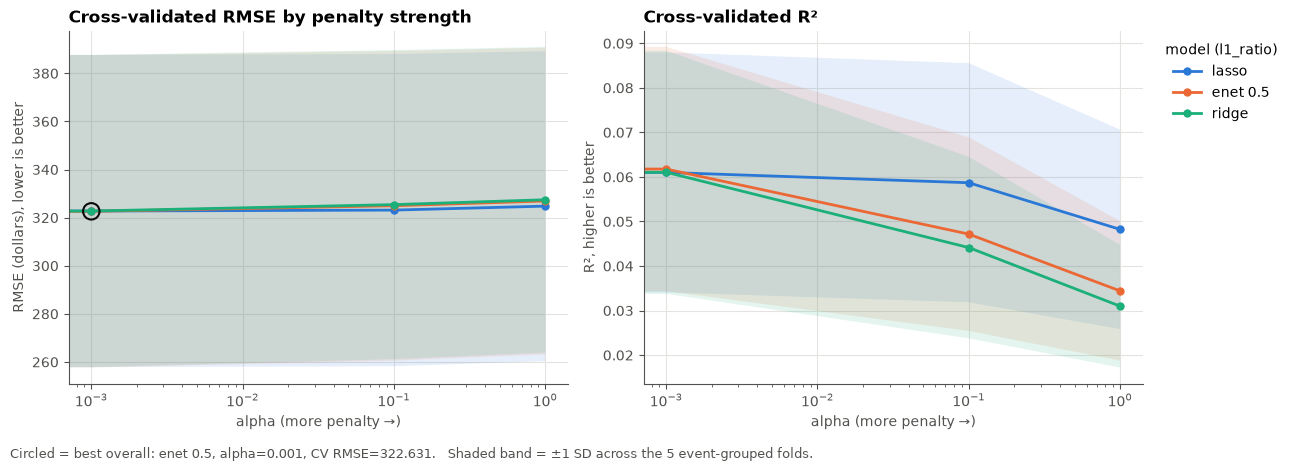

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, g in all_results.groupby("model", sort=False):
    g = g.sort_values("alpha")
    c = MODEL_COLORS[name]
    for ax, metric in zip(axes, ["RMSE", "R^2"]):
        mean, sd = g[f"{metric} (mean)"], g[f"{metric} (sd)"]
        ax.plot(g["alpha"], mean, color=c, lw=2, marker="o", ms=5, label=name)
        ax.fill_between(g["alpha"], mean - sd, mean + sd, color=c, alpha=0.12, lw=0)

best = all_results.loc[all_results["RMSE (mean)"].idxmin()]
axes[0].scatter(best["alpha"], best["RMSE (mean)"], s=140, facecolor="none", edgecolor=INK, lw=1.5, zorder=5)

axes[0].set(title="Cross-validated RMSE by penalty strength", xscale="log",
            xlabel="alpha (more penalty →)", ylabel=f"RMSE ({UNITS}), lower is better")
axes[1].set(title="Cross-validated R²", xscale="log",
            xlabel="alpha (more penalty →)", ylabel="R², higher is better")
axes[1].legend(title="model (l1_ratio)", loc="upper left", bbox_to_anchor=(1.02, 1))
fig.text(0.01, -0.03, f"Circled = best overall: {best['model']}, alpha={best['alpha']:g}, "
         f"CV RMSE={best['RMSE (mean)']:.3f}.   Shaded band = ±1 SD across the 5 event-grouped folds.",
         color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()


In [14]:
best_per_model = all_results.loc[all_results.groupby("model", sort=False)["RMSE (mean)"].idxmin()]

fitted, coef_table, rows = {}, {}, []
for _, r in best_per_model.iterrows():
    m = clone(make_model(r["alpha"], l1_ratios[r["model"]])).fit(X_train, y_train)
    fitted[r["model"]] = m
    names = m.named_steps["prep"].get_feature_names_out()
    coefs = pd.Series(m.named_steps["model"].coef_, index=names)
    coef_table[r["model"]] = coefs
    pred = m.predict(X_test)
    rows.append({
        "model": r["model"], "l1_ratio": l1_ratios[r["model"]], "best alpha": r["alpha"],
        "features kept": int((coefs != 0).sum()), "features total": len(coefs),
        "% kept": 100 * (coefs != 0).mean(),
        "CV RMSE": r["RMSE (mean)"], "test RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "test R²": r2_score(y_test, pred),
    })

coef_table = pd.DataFrame(coef_table)                 # features x models
summary = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
display(summary.style.format({"best alpha": "{:g}", "% kept": "{:.1f}%", "CV RMSE": "{:.4f}",
                              "test RMSE": "{:.4f}", "test R²": "{:.4f}"})
               .bar(subset=["% kept"], color="#b7d3f6", vmin=0, vmax=100)
               .set_caption("Best alpha per model, refit on all training data"))


/Users/aosr/Desktop/ML 1/m1_final_project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.787037e+09, tolerance: 1.163e+07
  model = cd_fast.sparse_enet_coordinate_descent(


,model,l1_ratio,best alpha,features kept,features total,% kept,CV RMSE,test RMSE,test R²
0,enet 0.5,0.500000,0.001,489,493,99.2%,322.6306,225.4399,0.1032
1,lasso,1.000000,0.001,466,493,94.5%,322.7439,225.6716,0.1014
2,ridge,0.000000,0.001,493,493,100.0%,322.7504,225.4648,0.1030


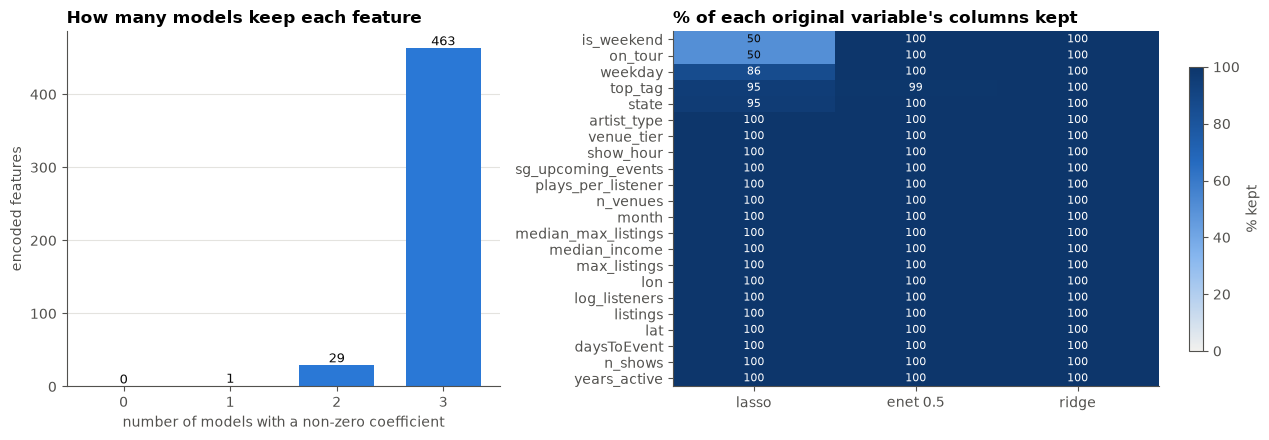

463 of 493 encoded features are kept by all 3 models


In [15]:
def original_feature(f):
    """map an encoded column name back to the raw column it came from"""
    f = f.split("__", 1)[1].removeprefix("missingindicator_")
    return max((c for c in num_cols + cat_cols if f == c or f.startswith(c + "_")), key=len)

kept = coef_table != 0
n_models = kept.shape[1]
kept_count = kept.sum(axis=1)

# (a) how many encoded features are kept by 0..5 models
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
counts = kept_count.value_counts().reindex(range(n_models + 1), fill_value=0)
axes[0].bar(counts.index, counts.values, color="#2a78d6", width=0.7)
for x, v in counts.items():
    axes[0].text(x, v, f"{v}", ha="center", va="bottom", fontsize=9, color=INK)
axes[0].set(title="How many models keep each feature", xlabel="number of models with a non-zero coefficient",
            ylabel="encoded features", xticks=range(n_models + 1))
axes[0].grid(axis="x", visible=False)

# (b) share of each raw column's encoded features that are kept, by model
by_raw = kept.groupby(kept.index.map(original_feature)).mean().mul(100)
by_raw = by_raw.loc[by_raw.mean(axis=1).sort_values().index]
im = axes[1].imshow(by_raw.values, aspect="auto", cmap=LinearSegmentedColormap.from_list(
    "seq", ["#f2f1ee", "#86b6ef", "#256abf", "#0d366b"]), vmin=0, vmax=100)
axes[1].set(title="% of each original variable's columns kept", yticks=range(len(by_raw)),
            yticklabels=by_raw.index, xticks=range(n_models), xticklabels=by_raw.columns)
axes[1].grid(False)
for i in range(by_raw.shape[0]):
    for j in range(by_raw.shape[1]):
        v = by_raw.iat[i, j]
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else INK)
fig.colorbar(im, ax=axes[1], label="% kept", shrink=0.8)
plt.tight_layout()
plt.show()

always_kept = kept_count[kept_count == n_models].index
print(f"{len(always_kept)} of {len(kept_count)} encoded features are kept by all {n_models} models")


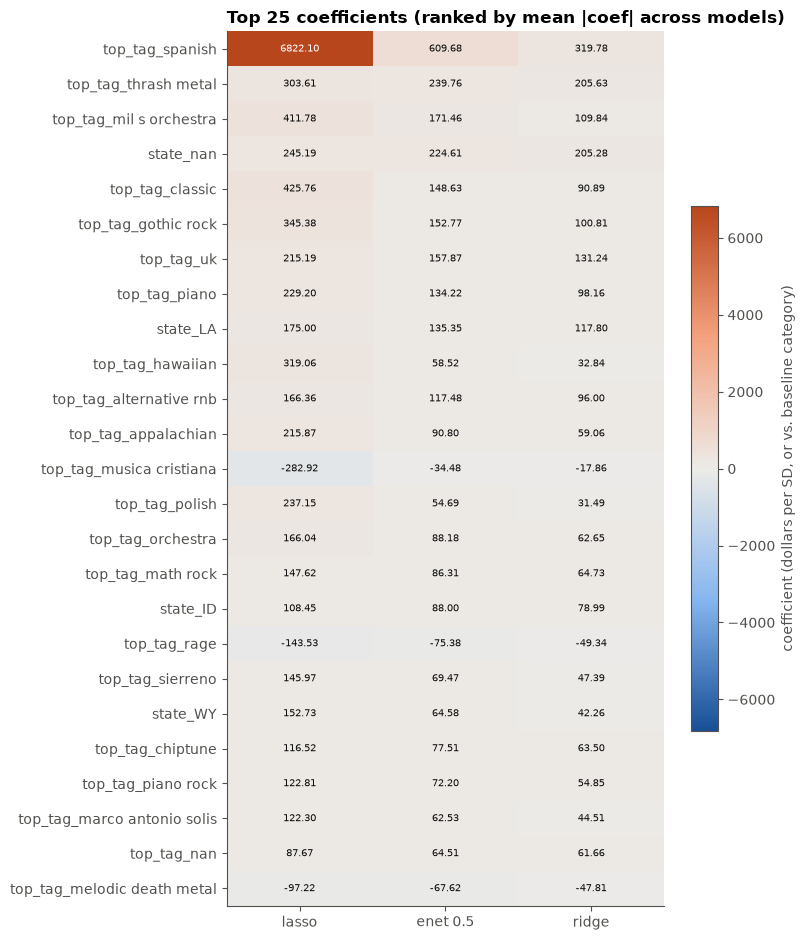

In [16]:
TOP_N = 25
top = coef_table.abs().mean(axis=1).sort_values(ascending=False).head(TOP_N).index
heat = coef_table.loc[top]
lim = heat.abs().to_numpy().max()

fig, ax = plt.subplots(figsize=(8, 0.32 * TOP_N + 1.5))
im = ax.imshow(heat.values, aspect="auto", cmap=DIVERGING, vmin=-lim, vmax=lim)
ax.set(yticks=range(TOP_N), yticklabels=[f.split("__", 1)[1] for f in top],
       xticks=range(n_models), xticklabels=heat.columns,
       title=f"Top {TOP_N} coefficients (ranked by mean |coef| across models)")
ax.grid(False)
for i in range(TOP_N):
    for j in range(n_models):
        v = heat.iat[i, j]
        ax.text(j, i, "0" if v == 0 else f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.6 * lim else INK)
fig.colorbar(im, ax=ax, label=f"coefficient ({UNITS} per SD, or vs. baseline category)", shrink=0.6)
plt.tight_layout()
plt.show()


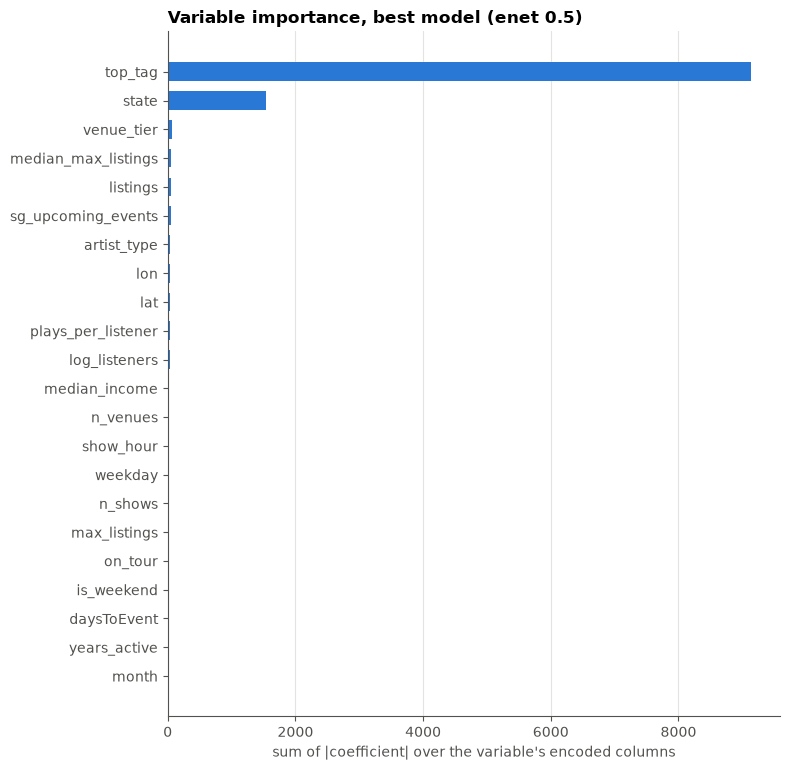

Note: categoricals with many levels (top_tag, state) add up many small dummies, so read this as 'total influence', not 'one-unit effect'.


In [17]:
best_name = summary.loc[0, "model"]
imp = (coef_table[best_name].abs().groupby(coef_table.index.map(original_feature)).sum()
       .sort_values())
imp = imp[imp > 0]

fig, ax = plt.subplots(figsize=(8, 0.3 * len(imp) + 1.2))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.65)
ax.set(title=f"Variable importance, best model ({best_name})",
       xlabel="sum of |coefficient| over the variable's encoded columns")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print("Note: categoricals with many levels (top_tag, state) add up many small dummies, "
      "so read this as 'total influence', not 'one-unit effect'.")


48 of 258,167 test predictions (0.0%) are <= $0 and are left out of the left plot (min prediction: $-33.15)


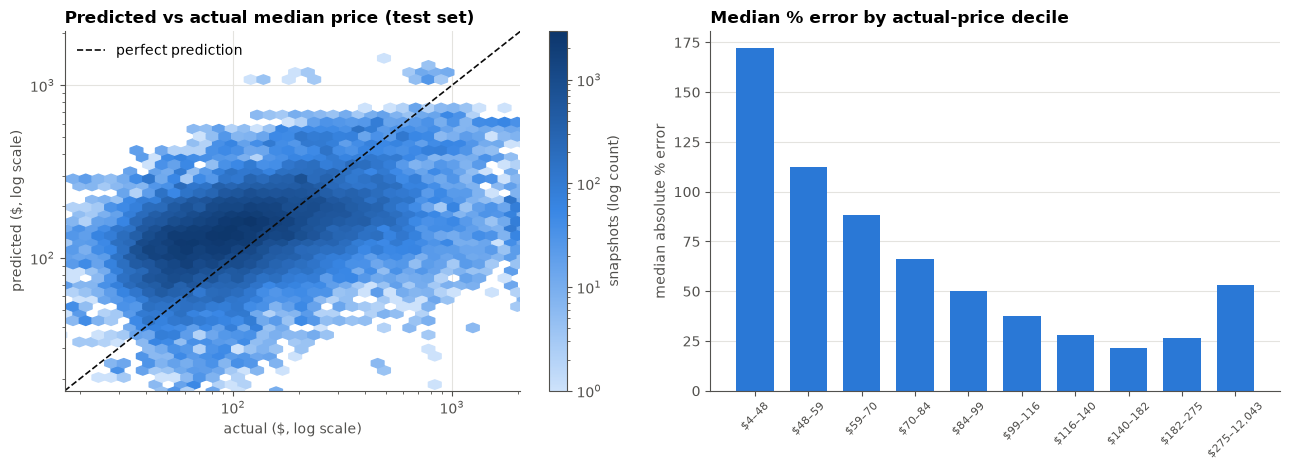

In [19]:
m = fitted[best_name]
pred = m.predict(X_test)
actual = np.asarray(np.exp(y_test) if Y_IS_LOG else y_test)
pred_d = np.asarray(np.exp(pred) if Y_IS_LOG else pred)

# a raw-price linear model can predict prices <= $0, which a log axis can't show
bad = pred_d <= 0
if bad.any():
    print(f"{bad.sum():,} of {len(pred_d):,} test predictions ({bad.mean():.1%}) are <= $0 "
          f"and are left out of the left plot (min prediction: ${pred_d.min():,.2f})")
ok = ~bad

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
hb = axes[0].hexbin(actual[ok], pred_d[ok], gridsize=60, bins="log", xscale="log", yscale="log",
                    cmap=LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#3987e5", "#0d366b"]), mincnt=1)

lo, hi = np.percentile(np.r_[actual, pred_d], [0.1, 99.9])
axes[0].plot([lo, hi], [lo, hi], color=INK, lw=1.2, ls="--", label="perfect prediction")
axes[0].set(title="Predicted vs actual median price (test set)", xlabel="actual ($, log scale)",
            ylabel="predicted ($, log scale)", xlim=(lo, hi), ylim=(lo, hi))
axes[0].legend(loc="upper left")
fig.colorbar(hb, ax=axes[0], label="snapshots (log count)")

# absolute % error by actual-price decile: where is the model worst?
err = pd.DataFrame({"actual": np.asarray(actual), "ape": np.abs(pred_d - actual) / actual * 100})
err["decile"] = pd.qcut(err["actual"], 10)
dec = err.groupby("decile", observed=True)["ape"].median()
axes[1].bar(range(10), dec.values, color="#2a78d6", width=0.7)
axes[1].set(title="Median % error by actual-price decile", ylabel="median absolute % error",
            xticks=range(10), xticklabels=[f"${iv.left:,.0f}–{iv.right:,.0f}" for iv in dec.index])
axes[1].tick_params(axis="x", rotation=45, labelsize=8)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
